In [2]:
# %pip install pandas numpy matplotlib scipy seaborn scikit-learn 
# DATA ANALYTICS - LIBRARY IMPORTS

# Data manipulation and analysis
import pandas as pd
# pd: Load CSV/Excel files, clean data, filter rows,
# join tables, group data, and handle missing values.

# Numerical computing
import numpy as np
# np: Arrays, mathematical operations, statistical
# calculations, and numerical transformations.

# Data visualization
import matplotlib
import matplotlib.pyplot as plt
# plt: Create line charts, bar charts, histograms,
# scatter plots, and customize chart layouts.

# Scientific and statistical computing
import scipy
# scipy: Statistical tests, probability distributions,
# optimization, and scientific calculations.

# Statistical data visualization
import seaborn as sns
# sns: Statistical charts, heatmaps, boxplots,
# distributions, and correlation visualizations.

# Machine learning
import sklearn
# sklearn: Data preprocessing, feature engineering,
# model training, model selection, and evaluation.

# Statistical modeling and inference
import statsmodels as sm

# File and directory paths
from pathlib import Path
# Path: Manage file paths across operating systems.

In [3]:
# Verify the installed library versions
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("SciPy version:", scipy.__version__)
print("Matplotlib version:", matplotlib.__version__)
print("Seaborn version:", sns.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Statsmodels version:", sm.__version__)

# pathlib is part of Python's standard library;
# it does not have a package version attribute like these libraries.
print("Path class imported:", Path)


Pandas version: 3.0.3
NumPy version: 2.4.6
SciPy version: 1.17.1
Matplotlib version: 3.11.0
Seaborn version: 0.13.2
Scikit-learn version: 1.9.0
Statsmodels version: 0.14.6
Path class imported: <class 'pathlib.Path'>


In [4]:
# create a datframe of the csv file
df = pd.read_csv(r"C:\Users\vasav\OneDrive\Desktop\DA_PROJECTS\Project_1\Delinquency_prediction_dataset - Copy.csv")

In [5]:
# To check how many rows and columns
print("Number of rows and columns:", df.shape)

Number of rows and columns: (500, 19)


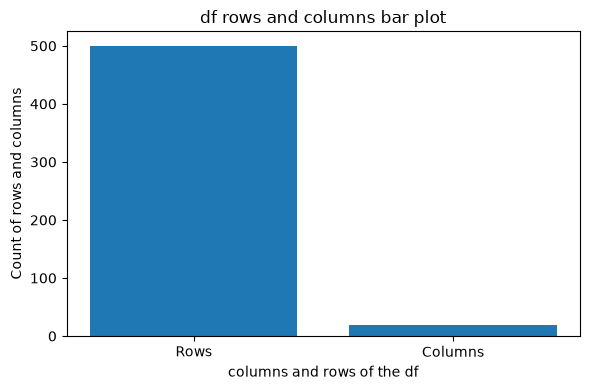

In [6]:
#bar plot for df columns and rows
total_rows, total_columns = df.shape
#Decide the figsize of the area of the chart
plt.figure(figsize = (6,4))
#decide the chart of the ploting
plt.bar(["Rows", "Columns"],
        [total_rows, total_columns])
#decide the title 
plt.title("df rows and columns bar plot")
#decide the x label 
plt.xlabel("columns and rows of the df")
#decide y label 
plt.ylabel("Count of rows and columns")
# figure size tight_layout
plt.tight_layout()
#show the plot
plt.show()

In [7]:
# To Print Columns Name
print("The columns names are :-", df.columns.tolist())

The columns names are :- ['Customer_ID', 'Age', 'Income', 'Credit_Score', 'Credit_Utilization', 'Missed_Payments', 'Delinquent_Account', 'Loan_Balance', 'Debt_to_Income_Ratio', 'Employment_Status', 'Account_Tenure', 'Credit_Card_Type', 'Location', 'Month_1', 'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6']


In [8]:
# To check DataTypes and Non-null Count
print("Info about the df", df.info())

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Customer_ID           500 non-null    str    
 1   Age                   500 non-null    int64  
 2   Income                461 non-null    float64
 3   Credit_Score          498 non-null    float64
 4   Credit_Utilization    500 non-null    float64
 5   Missed_Payments       500 non-null    int64  
 6   Delinquent_Account    500 non-null    int64  
 7   Loan_Balance          471 non-null    float64
 8   Debt_to_Income_Ratio  500 non-null    float64
 9   Employment_Status     500 non-null    str    
 10  Account_Tenure        500 non-null    int64  
 11  Credit_Card_Type      500 non-null    str    
 12  Location              500 non-null    str    
 13  Month_1               500 non-null    str    
 14  Month_2               500 non-null    str    
 15  Month_3               500 non-null

no need of type conversation already shorted

In [42]:
# FUNCTION: NULL AND NON-NULL VALUE ANALYSIS
# PURPOSE: Calculate null and non-null counts and percentages for one Series

def null_analysis(series):

    # Count missing values in the input Series
    null_count = series.isna().sum()

    # Calculate the percentage of missing values
    null_percentage = (
        (null_count / len(series)) * 100
        if len(series) > 0 else 0
    )

    # Count non-missing values in the input Series
    non_null_count = series.notna().sum()

    # Calculate the percentage of non-missing values
    non_null_percentage = (
        (non_null_count / len(series)) * 100
        if len(series) > 0 else 0
    )

    # Return all results as a Pandas Series
    return pd.Series({
        "Null_Count": null_count,
        "Null_Percentage": round(null_percentage, 2),
        "Non_Null_Count": non_null_count,
        "Non_Null_Percentage": round(non_null_percentage, 2)
    })


# Apply null_analysis to every column in the DataFrame
null_summary = df.apply(null_analysis)

# Transpose so each column appears as one row
null_summary = null_summary.T

# Display null and non-null statistics for all columns
display(null_summary)

,Null_Count,Null_Percentage,Non_Null_Count,Non_Null_Percentage
Customer_ID,0.0,0.0,500.0,100.0
Age,0.0,0.0,500.0,100.0
Income,39.0,7.8,461.0,92.2
Credit_Score,2.0,0.4,498.0,99.6
Credit_Utilization,0.0,0.0,500.0,100.0
Missed_Payments,0.0,0.0,500.0,100.0
Delinquent_Account,0.0,0.0,500.0,100.0
Loan_Balance,29.0,5.8,471.0,94.2
Debt_to_Income_Ratio,0.0,0.0,500.0,100.0
Employment_Status,0.0,0.0,500.0,100.0


In [39]:
#total null and it's percentage
total_nulls = df.isna().sum().sum()
total_nulls_percentage = ((total_nulls / df.size * 100))
print("total null values in cells -----> ",total_nulls)
print("total null values in cells percentage-----> ",total_nulls_percentage)

total null values in cells ----->  70
total null values in cells percentage----->  0.7368421052631579


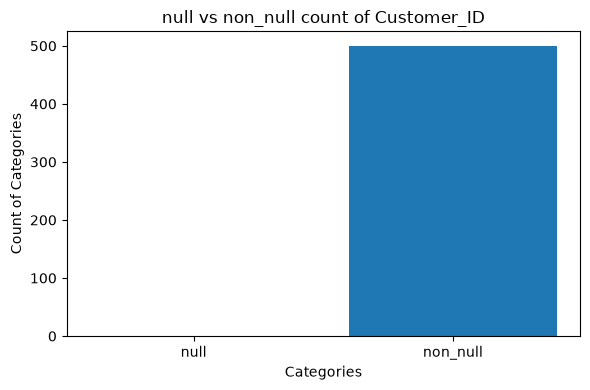

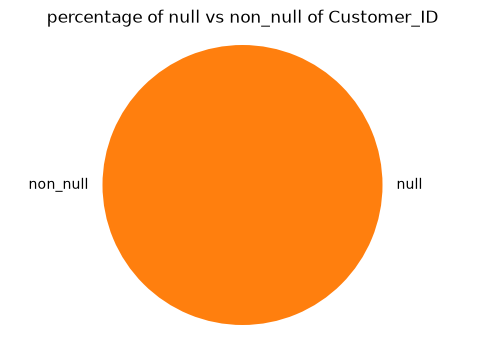

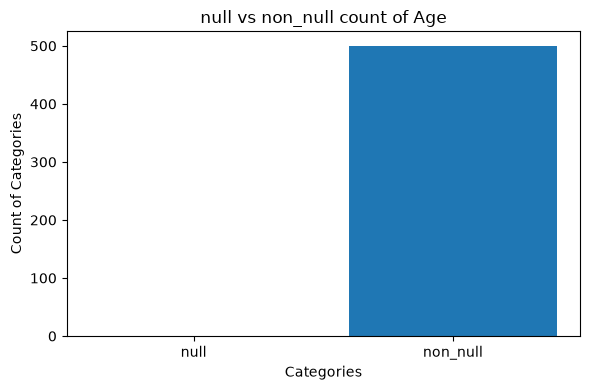

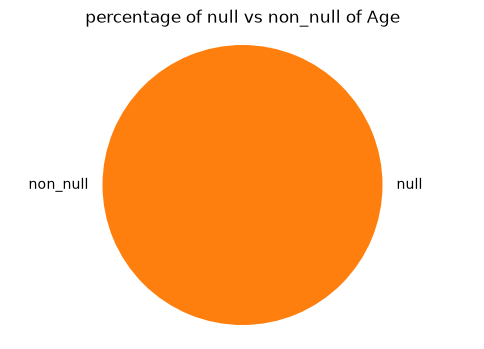

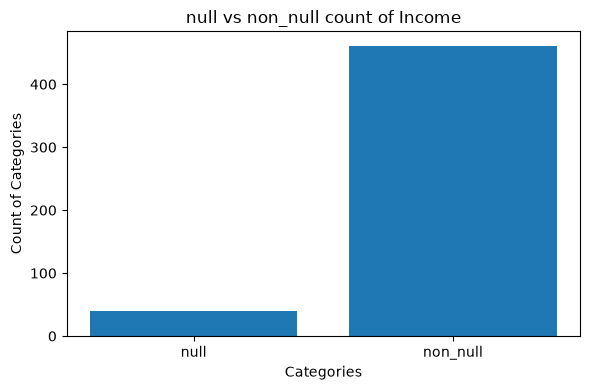

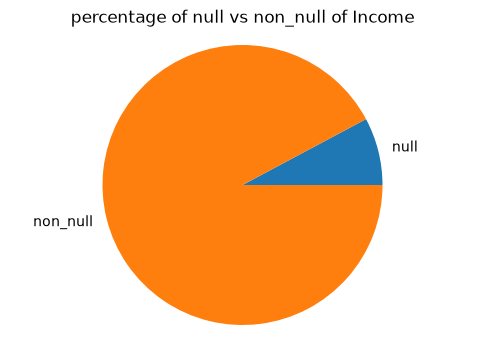

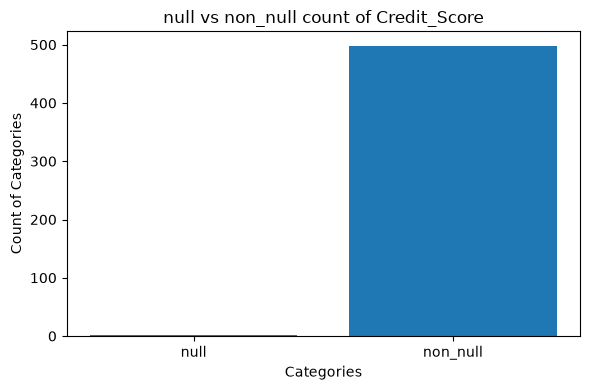

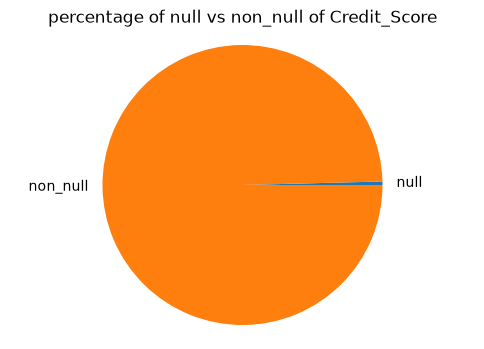

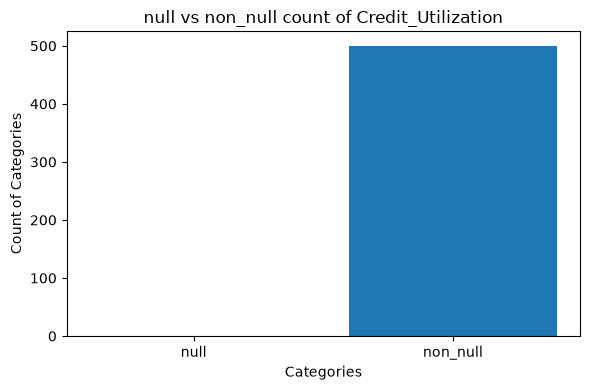

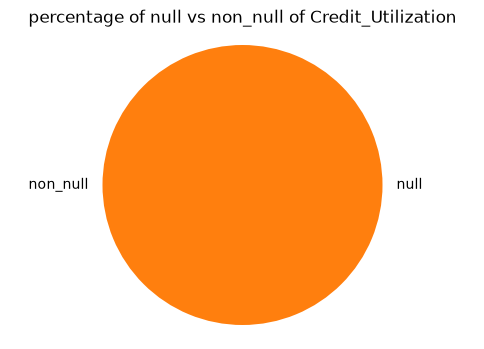

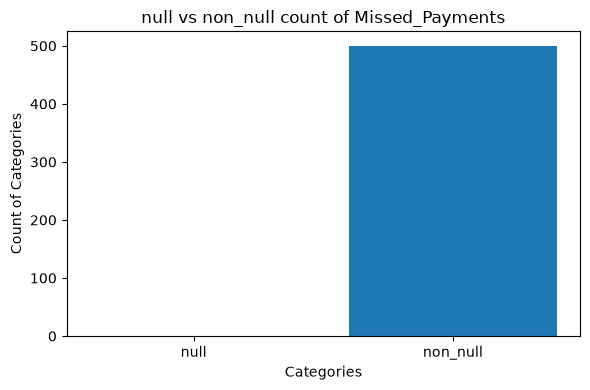

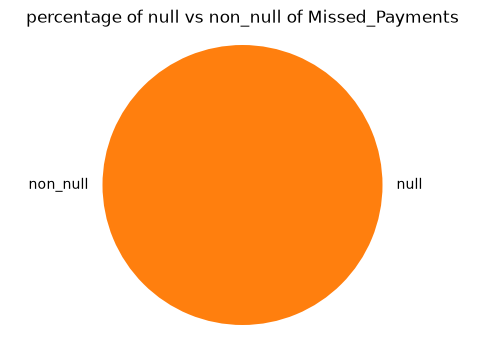

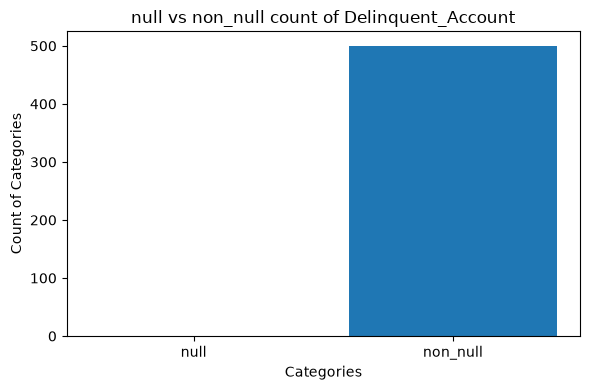

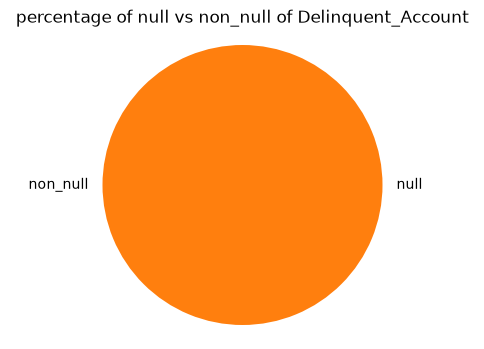

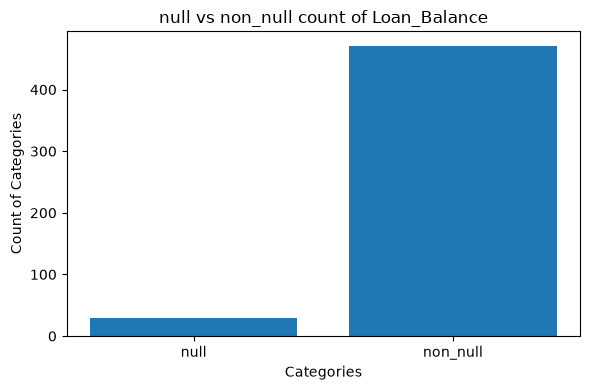

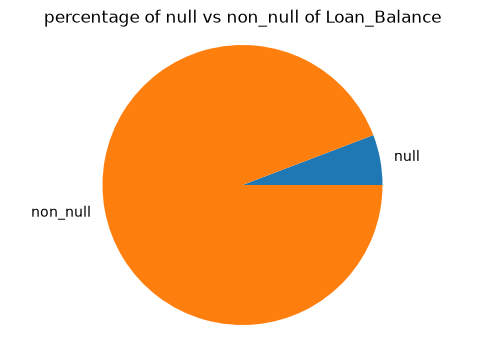

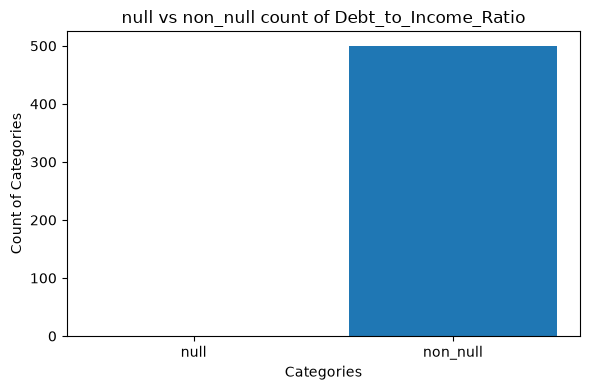

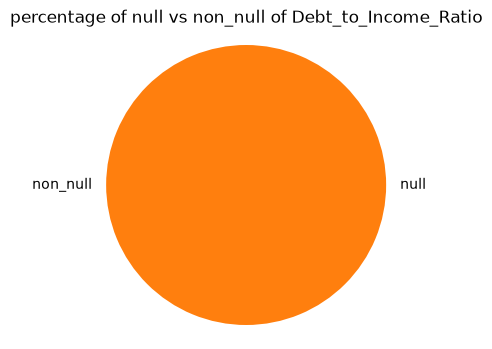

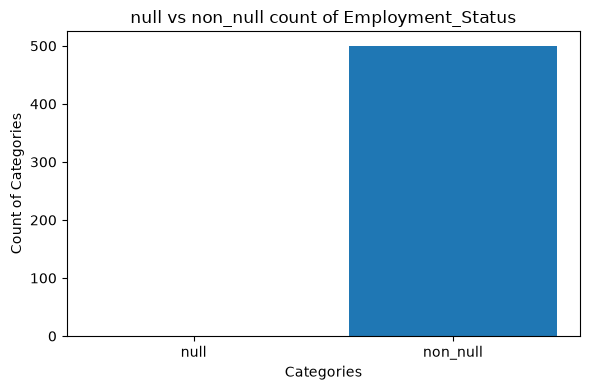

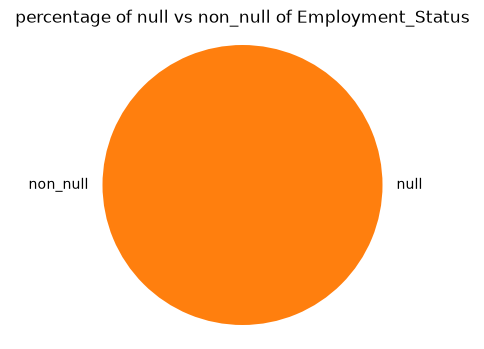

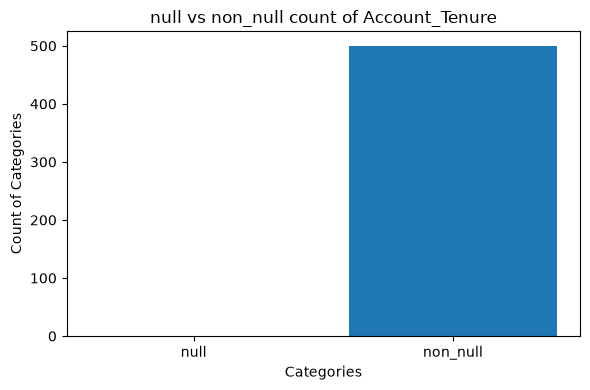

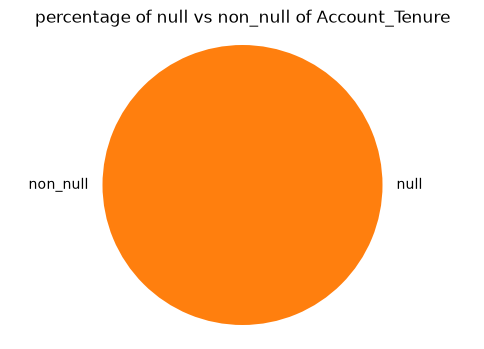

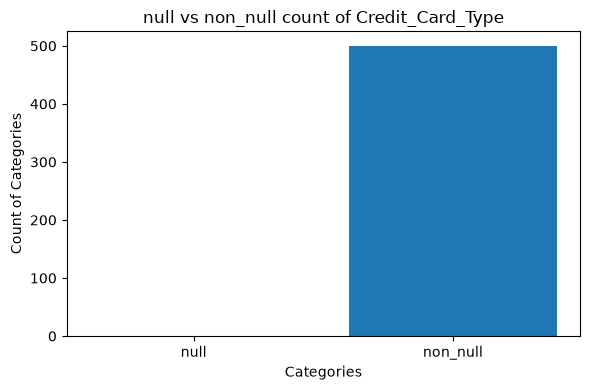

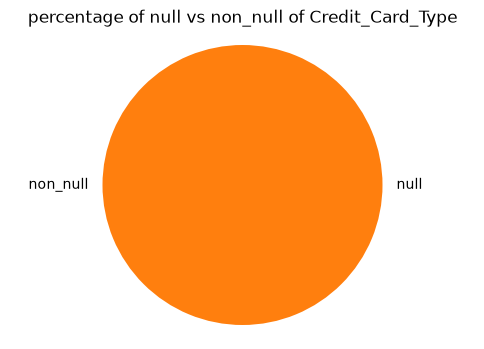

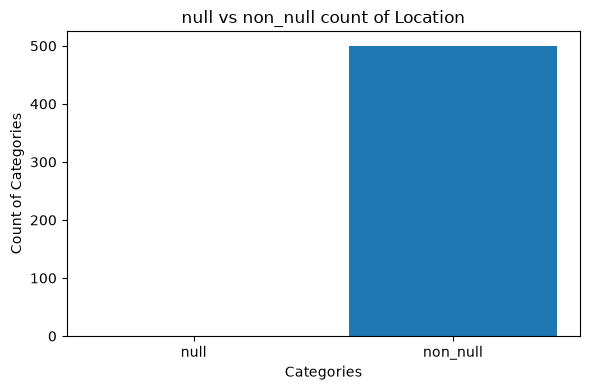

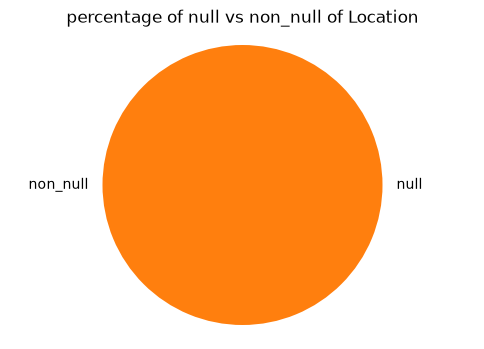

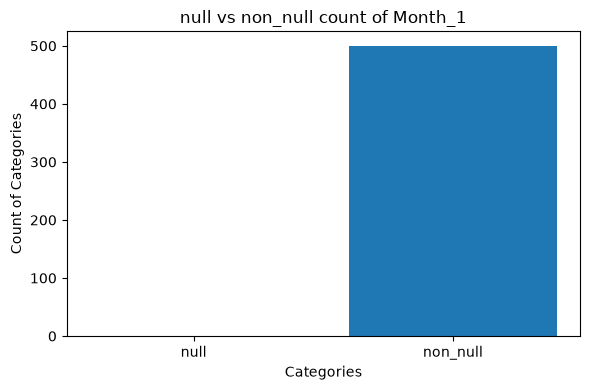

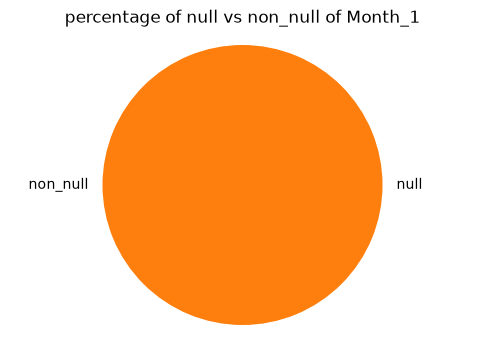

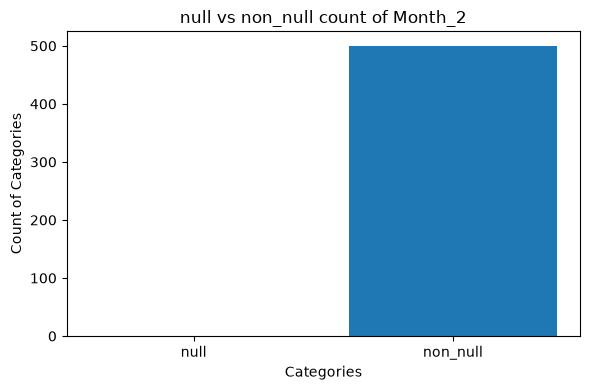

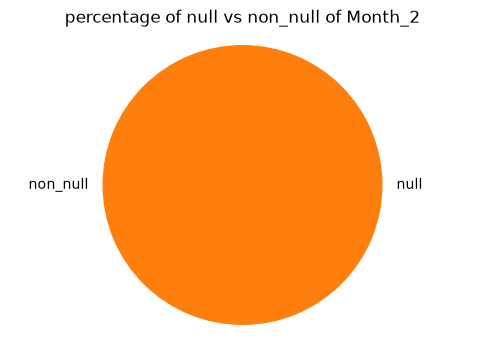

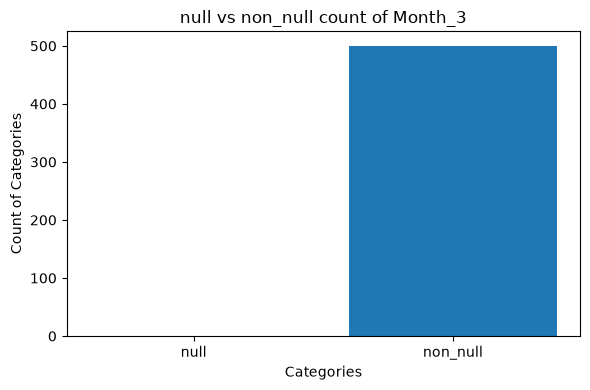

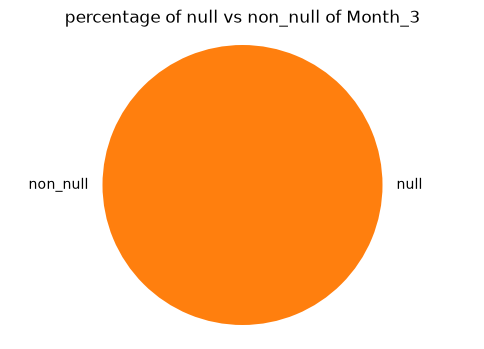

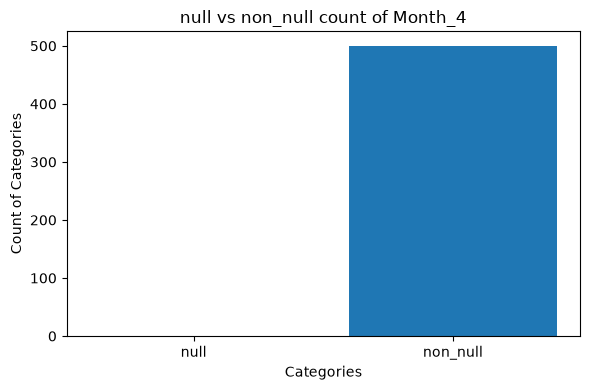

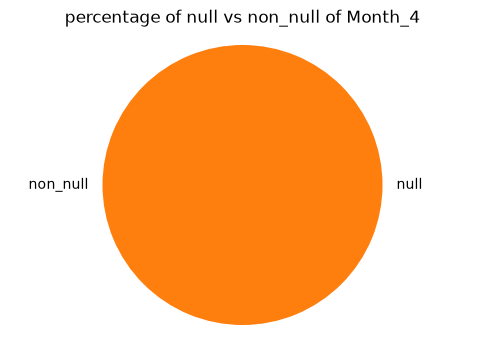

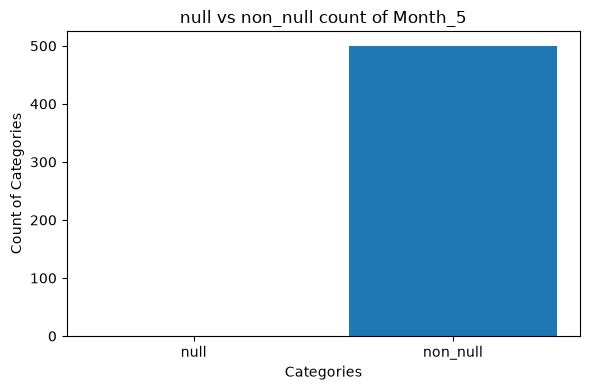

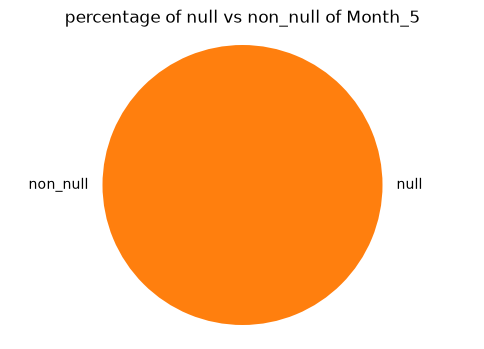

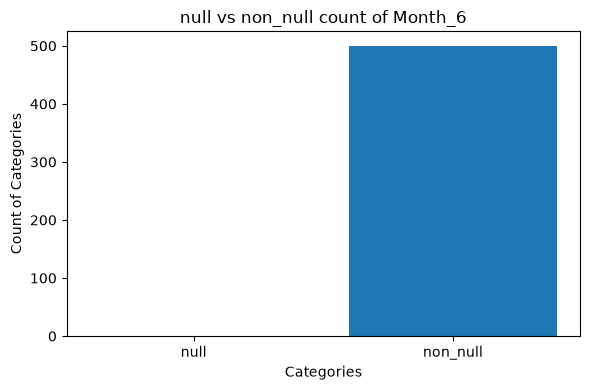

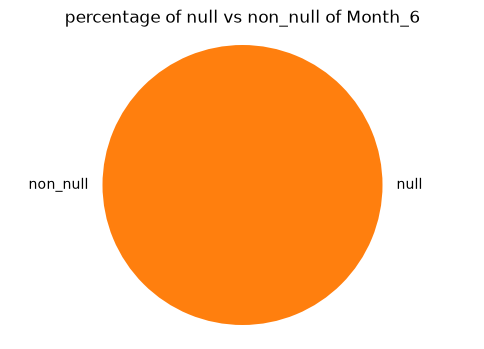

In [10]:
#plot bar and pie chart for the null and notnull values
#standardize the columns name 
null_summary.columns = [
    "null_count",
    "null_percentage",
    "non_null_count",
    "non_null_percentage"
]
for column in null_summary.index:
    #get value of null_count and null_percentage using loc
    null_count = null_summary.loc[column , "null_count"]
    null_percentage = null_summary.loc[column, "null_percentage"]
    #get value of non_null_count and nun_null_percentage using loc
    non_null_count = null_summary.loc[column, "non_null_count"]
    non_null_percentage = null_summary.loc[column, "non_null_percentage"]
    #decide the figure size of bar 
    plt.figure(figsize = (6,4))
    #decide the plot 
    plt.bar(
        ["null", "non_null"],
        [null_count, non_null_count]
    )
    #decide the title
    plt.title(f"null vs non_null count of {column}")
    #decide the x label
    plt.xlabel("Categories")
    #decide the y label 
    plt.ylabel("Count of Categories")
    #tight the layout for better space managment 
    plt.tight_layout()
    #show plot
    plt.show()

    #decide the figure size of the pie
    plt.figure(figsize =(6,4))
    #decide the chart
    plt.pie(
        [null_percentage , non_null_percentage],
        labels = ["null", "non_null"]
    )
    #decide the title 
    plt.title(f"percentage of null vs non_null of {column}")
    plt.axis("equal")
    plt.show()

In [11]:
#for particular columns data view of top 
df['Employment_Status'].head(100)

0               EMP
1     Self-employed
2     Self-employed
3        Unemployed
4     Self-employed
          ...      
95          retired
96    Self-employed
97       Unemployed
98         employed
99          retired
Name: Employment_Status, Length: 100, dtype: str

In [12]:
#for particular columns data view of bottom 
df['Employment_Status'].tail(100)

400              EMP
401       Unemployed
402              EMP
403         employed
404          retired
           ...      
495          retired
496       Unemployed
497         Employed
498         Employed
499    Self-employed
Name: Employment_Status, Length: 100, dtype: str

In [13]:
# FUNCTION: VIEW TOP, MIDDLE, AND BOTTOM 100 VALUES
# PURPOSE: Inspect values in a Series before correcting data types

def view_100(series):

    # Display the column name
    print(f"\n{'=' * 80}")
    print(f"COLUMN NAME: {series.name}")
    print(f"{'=' * 80}")

    # View the first 100 values
    print("\n--- TOP 100 VALUES ---")
    display(series.head(100))

    # Calculate the starting position for the middle 100 values
    middle_start = max(0, (len(series) // 2) - 50)

    # View the middle 100 values
    print("\n--- MIDDLE 100 VALUES ---")
    display(series.iloc[middle_start:middle_start + 100])

    # View the last 100 values
    print("\n--- BOTTOM 100 VALUES ---")
    display(series.tail(100))


In [14]:
# Loop through every column in the DataFrame
for column in df.columns:

    # Inspect top, middle, and bottom values
    view_100(df[column])


COLUMN NAME: Customer_ID

--- TOP 100 VALUES ---


0     CUST0001
1     CUST0002
2     CUST0003
3     CUST0004
4     CUST0005
        ...   
95    CUST0096
96    CUST0097
97    CUST0098
98    CUST0099
99    CUST0100
Name: Customer_ID, Length: 100, dtype: str


--- MIDDLE 100 VALUES ---


200    CUST0201
201    CUST0202
202    CUST0203
203    CUST0204
204    CUST0205
         ...   
295    CUST0296
296    CUST0297
297    CUST0298
298    CUST0299
299    CUST0300
Name: Customer_ID, Length: 100, dtype: str


--- BOTTOM 100 VALUES ---


...

0        Late
1     On-time
2        Late
3        Late
4        Late
       ...   
95     Missed
96    On-time
97    On-time
98       Late
99       Late
Name: Month_6, Length: 100, dtype: str


--- MIDDLE 100 VALUES ---


200    On-time
201     Missed
202       Late
203     Missed
204    On-time
        ...   
295     Missed
296    On-time
297     Missed
298    On-time
299    On-time
Name: Month_6, Length: 100, dtype: str


--- BOTTOM 100 VALUES ---


400       Late
401       Late
402    On-time
403     Missed
404     Missed
        ...   
495       Late
496     Missed
497     Missed
498     Missed
499    On-time
Name: Month_6, Length: 100, dtype: str

In [15]:
#to fet the count of the uniue values 
def unique_value(series):
    display(series.nunique())
unique_value(df["Employment_Status"])

6

In [16]:
#to get the unique value as text_array
df.Employment_Status.unique()

<ArrowStringArray>
['EMP', 'Self-employed', 'Unemployed', 'employed', 'Employed', 'retired']
Length: 6, dtype: str

In [23]:
#to view the unique values and it's count function
def unique_value_count(series):
    print("The unique_values and its counts -----> ", series.value_counts())
    print("No count of unique_values -----> ",series.nunique())
for Column in df.columns:
    unique_value_count(df[Column])

The unique_values and its counts ----->  Customer_ID
CUST0001    1
CUST0002    1
CUST0003    1
CUST0004    1
CUST0005    1
           ..
CUST0496    1
CUST0497    1
CUST0498    1
CUST0499    1
CUST0500    1
Name: count, Length: 500, dtype: int64
No count of unique_values ----->  500
The unique_values and its counts ----->  Age
50    18
41    15
52    15
19    14
49    13
56    12
69    12
25    12
61    12
66    12
45    12
20    11
39    11
42    11
59    11
65    11
32    10
40    10
68    10
54    10
43    10
71    10
46     9
57     9
72     9
24     9
26     9
18     9
28     8
70     8
53     8
44     8
33     8
74     8
31     8
37     8
23     8
58     8
38     7
47     7
64     7
35     7
21     7
34     7
62     7
36     6
29     6
63     6
55     5
67     5
51     5
22     5
60     4
48     4
30     4
73     4
27     1
Name: count, dtype: int64
No count of unique_values ----->  57
The unique_values and its counts ----->  Income
90353.0     6
116570.0    5
42350.0     5
16558

In [41]:
# duplicated count and in percentage 
def duplicated_count(series):
    print("The exact duplicated count", series.duplicated().sum())
    print("The percentage of duplicated", (series.duplicated().sum() / len(df)) * 100) 
# for Columns_1 in df.columns:
#     duplicated_count(df[Columns_1])
duplicated_count(df)

The exact duplicated count 0
The percentage of duplicated 0.0
